# Forecasting & S&OP Planning - walkthrough

**Fictional hardware company, synthetic data.** This notebook narrates the project: the inputs a planning team works with, a leakage-safe
backtest, forecast-value-added at every step, uncertainty, and what forecast error costs in inventory and service.

*Run `python src/run_all.py` once first (it saves the backtest this notebook reads).*

In [1]:
import sys, copy
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd
from IPython.display import Image, display
import features, evaluate, plots
from run_all import assemble
pd.set_option('display.width', 200, 'display.max_columns', 30, 'display.float_format', lambda x: f'{x:,.3f}')
FIG, TAB = ROOT / 'outputs' / 'figures', ROOT / 'outputs' / 'tables'
show = lambda name, w=900: display(Image(filename=str(FIG / name), width=w))

## 1. The data - what a planning team actually works with

36 SKUs, 6 product lines, Jan-2020 to Dec-2025. Orders are the forecast target.

In [2]:
D = features.load_data(ROOT / 'data')
print('SKUs:', len(D.skus), '| months:', len(D.dates), '|', D.dates[0].date(), 'to', D.dates[-1].date())
tables = {p.stem: pd.read_csv(p).shape for p in sorted((ROOT / 'data' / 'raw').glob('*.csv'))}
print(tables)
D.sku_master[['sku', 'product_line', 'tier', 'generation', 'launch_date', 'eol_date', 'asp_usd', 'base_lead_time_weeks']].head(8)

SKUs: 36 | months: 72 | 2020-01-01 to 2025-12-01
{'competitor': (432, 7), 'events': (69, 4), 'leading_indicators': (432, 4), 'macro': (72, 4), 'marketing': (432, 5), 'operations': (432, 5), 'promo_calendar': (2592, 4), 'sales_history': (2592, 6), 'sku_master': (36, 14), 'supply_chain': (432, 5)}


,sku,product_line,tier,generation,launch_date,eol_date,asp_usd,base_lead_time_weeks
0,PC-E1,Client PCs,Entry,1,2018-01-01,2024-11-01,650.000,10
1,PC-E2,Client PCs,Entry,2,2023-05-01,NaN,702.000,10
2,PC-M1,Client PCs,Mainstream,1,2018-01-01,2025-06-01,"1,000.000",10
3,PC-M2,Client PCs,Mainstream,2,2024-05-01,NaN,"1,080.000",10
4,PC-P1,Client PCs,Premium,1,2018-01-01,2025-09-01,"1,800.000",10
5,PC-P2,Client PCs,Premium,2,2023-05-01,NaN,"1,944.000",10
6,AC-E1,Accessories & Peripherals,Entry,1,2018-01-01,2025-08-01,80.000,6
7,AC-E2,Accessories & Peripherals,Entry,2,2024-10-01,NaN,86.400,6


In [3]:
pd.read_csv(ROOT / 'data' / 'processed' / 'panel.csv').head(3).T

,0,1,2
date,2020-01-01,2020-02-01,2020-03-01
sku,PC-E1,PC-E1,PC-E1
orders,7889,7745,7636
shipments,7889,7745,7636
backlog_units,0,0,0
sales_forecast_3m_ahead,13955,8210,12219
product_line,Client PCs,Client PCs,Client PCs
tier,Entry,Entry,Entry
generation,1,1,1
asp_usd,650.000,650.000,650.000


### Demand history and the supply shortage

The company's order history includes a pandemic surge, a component shortage (customers over-order, supply is capped), a post-shortage
digestion dip, an AI-infrastructure ramp in enterprise lines, and an OS-refresh bump in PCs in 2025.

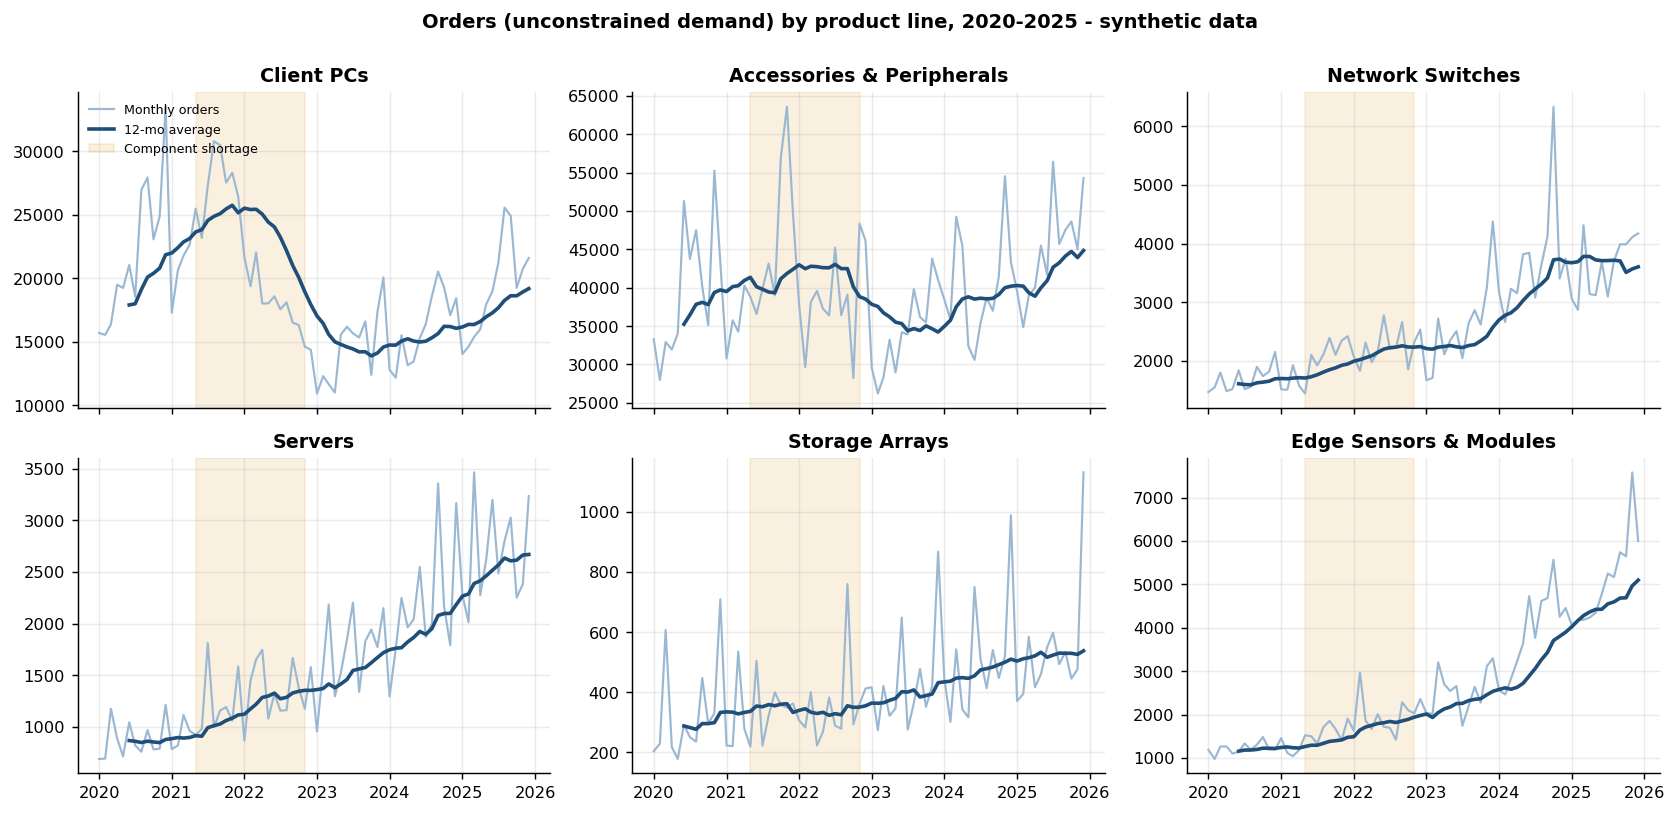

In [4]:
show('01_demand_history.png', 1100)

### Why we forecast **orders**, not shipments

During the shortage, shipments were capped by supply and a backlog built. A model trained on shipments would "learn" that demand fell.

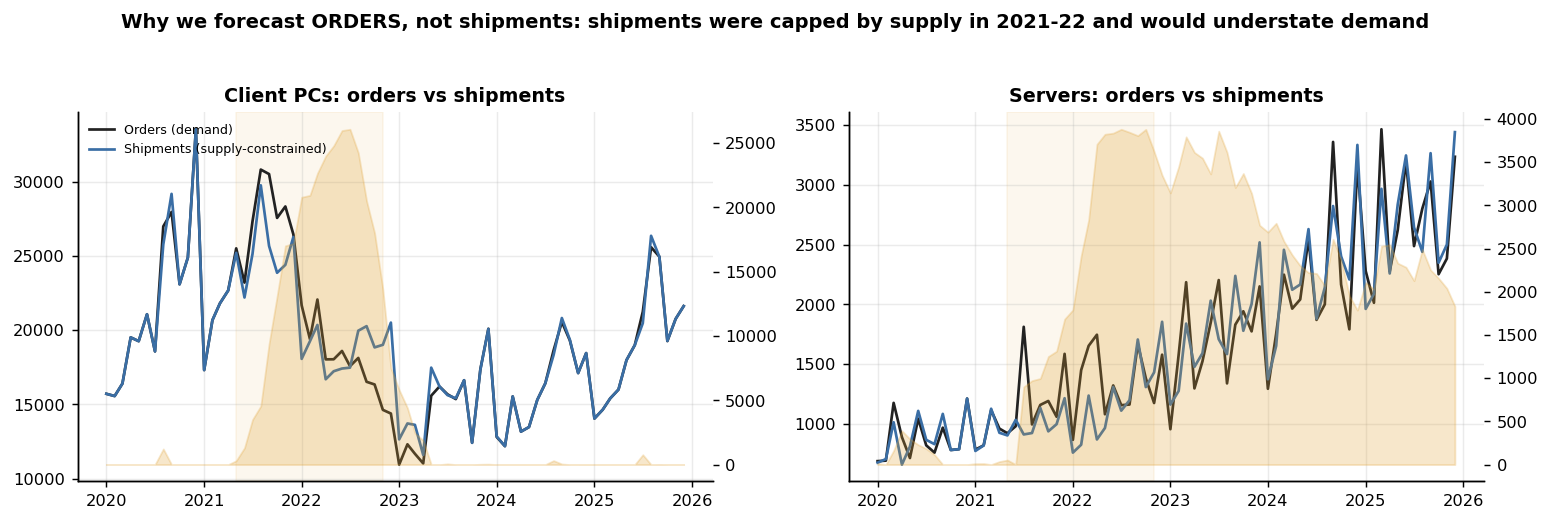

In [5]:
show('03_orders_vs_shipments.png', 1050)

### Seasonality differs by line

Enterprise lines peak at quarter-end months; consumer lines at back-to-school and the holidays.

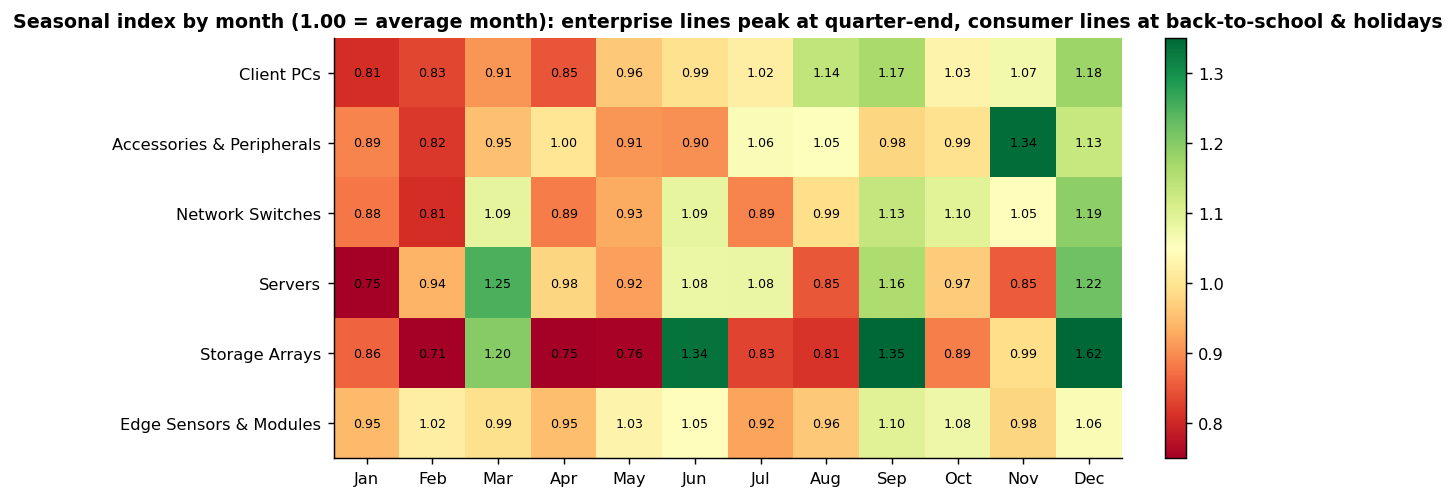

In [6]:
show('02_seasonality_heatmap.png', 900)

### External and operational inputs (example: Servers)

Pipeline, competitor price and share, macro, commodity prices and supplier lead time all feed the planning process.

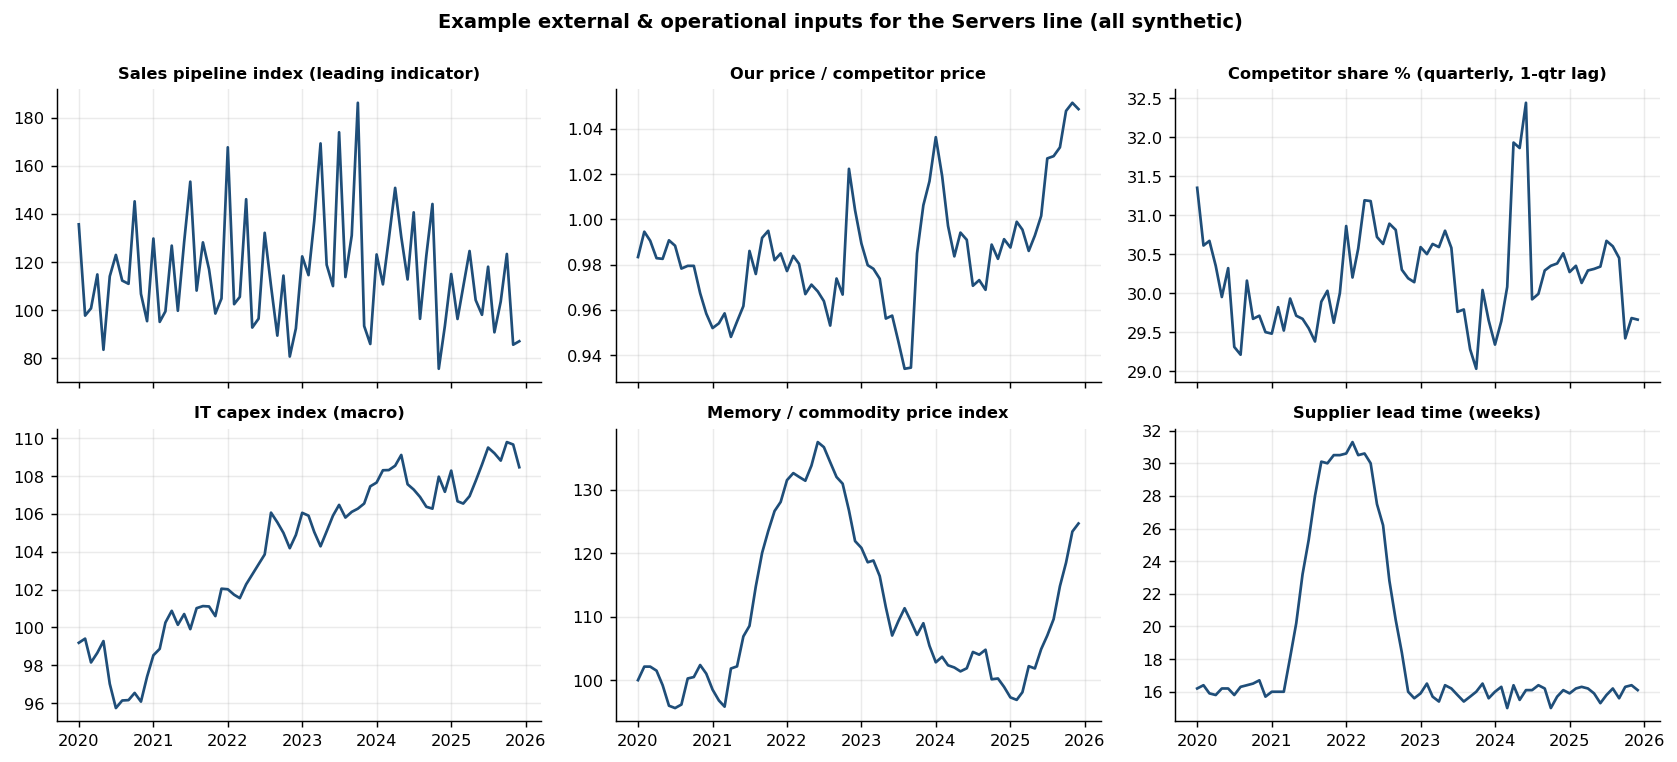

In [7]:
show('04_external_inputs_example.png', 1100)

### ABC / XYZ segmentation - where to focus review time

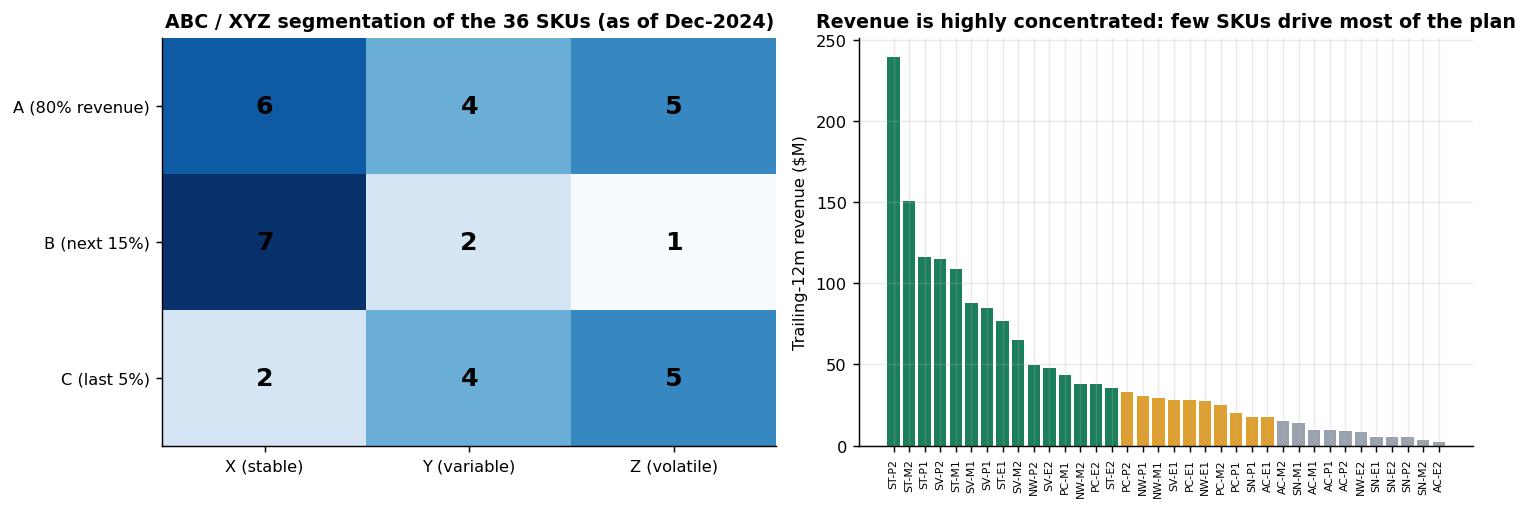

,sku,line,revenue,cv,cls,abc,xyz
29,ST-P2,Storage Arrays,"239,112,000.000",0.600,smooth,A,Z
27,ST-M2,Storage Arrays,"150,400,800.000",0.828,erratic,A,Z
28,ST-P1,Storage Arrays,"116,400,000.000",0.368,smooth,A,Y
23,SV-P2,Servers,"115,182,000.000",0.275,smooth,A,X
26,ST-M1,Storage Arrays,"108,790,000.000",0.622,erratic,A,Z
20,SV-M1,Servers,"87,540,000.000",0.362,smooth,A,Y
22,SV-P1,Servers,"84,465,000.000",0.531,erratic,A,Y
24,ST-E1,Storage Arrays,"76,480,000.000",0.235,smooth,A,X
21,SV-M2,Servers,"65,221,200.000",0.845,smooth,A,Z
17,NW-P2,Network Switches,"49,779,360.000",0.525,smooth,A,Y


In [8]:
show('05_abc_xyz.png', 1000)
seg = plots.abc_xyz(D)
seg.head(10)[['sku', 'line', 'revenue', 'cv', 'cls', 'abc', 'xyz']]

## 2. Features and a leakage test

Each feature is tagged by when it is known. *Origin* features are observed up to forecast origin `o`; *plan* features (promo calendar,
marketing budget, roadmap dates, announced events) are known in advance for the target month `T = o + h`.

In [9]:
F = features.build_feature_table(D)
print('feature rows (origin x horizon x SKU):', len(F))
print('\nCore (history / calendar / lifecycle):', features.CORE_COLS)
for g, cols in features.EXOG_GROUPS.items():
    print(f'  {g}: {cols}')

feature rows (origin x horizon x SKU): 6480

Core (history / calendar / lifecycle): ['h', 'lag0', 'lag1', 'lag2', 'lag5', 'seas12', 'seas24', 'm3', 'm6', 'm12', 'sd6', 'mom', 'yoy', 'grp_mom', 'line_mom', 'month_sin', 'month_cos', 'is_qtr_end', 'age_T', 'to_eol_T', 'gen', 'tier', 'line_code', 'hist_len']
  Promotions & pricing plan: ['promo_T', 'depth_T', 'promo_o']
  Marketing plan: ['mkt_ratio']
  Known events: ['refresh_T']
  Leading indicator (pipeline / traffic): ['li_o', 'li_chg3']
  Competitor: ['rel_px_o', 'rel_px_chg3', 'comp_share_o', 'comp_launch_3m']
  Macro & commodity: ['macro_o', 'macro_chg3', 'commodity_o']
  Supply chain & operations: ['lead_o', 'alloc_o', 'otd_o', 'yield_o', 'backlog_ratio']


**Leakage test.** If I corrupt every order observed *after* month 49 and rebuild the features, features for origins up to month 49 must not change.

In [10]:
D2 = copy.deepcopy(D)
D2.Y[50:, :] = D2.Y[50:, :] * 3 + 17        # corrupt the 'future'
F2 = features.build_feature_table(D2)
feat_cols = features.CORE_COLS + features.EXOG_COLS
a = F[F['o'] <= 49].reset_index(drop=True)[feat_cols]
b = F2[F2['o'] <= 49].reset_index(drop=True)[feat_cols]
print('Features identical for all origins <= 49 after corrupting the future:', np.allclose(a.to_numpy(float), b.to_numpy(float), equal_nan=True))

Features identical for all origins <= 49 after corrupting the future: True


## 3. Rolling-origin backtest

For every origin from Jul-2023 to Sep-2025 each model is re-fit on data available then and forecasts 1, 3 and 6 months ahead.
`src/run_all.py` runs this (about 2 minutes) and saves `backtest_forecasts.csv`; here we load it. Weights for the blend and the consensus were chosen on **2024 only**.

In [11]:
fc_raw = pd.read_csv(TAB / 'backtest_forecasts.csv')
fc, info = assemble(fc_raw, D, F)
print('models:', sorted(fc['model'].unique()))
print('GBM share in GBM-vs-ETS blend (2024 validation):', info['w'], '| share on statistical GBM in consensus:', info['wc'])
info['cgrid']

models: ['blend', 'consensus', 'gbm_core', 'gbm_full', 'ma3', 'naive', 'sales_fc', 'snaive', 'stat']
GBM share in GBM-vs-ETS blend (2024 validation): 1.0 | share on statistical GBM in consensus: 0.6


,weight_stat_model,val_wmape_rev
0,0.000,0.323
1,0.100,0.308
2,0.200,0.296
3,0.300,0.286
4,0.400,0.279
5,0.500,0.276
6,0.600,0.276
7,0.700,0.279
8,0.800,0.288
9,0.900,0.301


## 4. Accuracy: revenue-weighted WMAPE and bias, 2025 test year, 3-month horizon

In [12]:
test = fc[(fc['T'] >= evaluate.TEST_START) & (fc['h'] == 3)]
models = ['snaive', 'naive', 'ma3', 'stat', 'sales_fc', 'gbm_core', 'gbm_full', 'consensus']
test = test[test['model'].isin(models)]
out = {}
for lv in ['sku', 'line', 'total']:
    t = evaluate.accuracy_table(test, level=lv).set_index('model')
    out[lv] = t['wmape_rev']
res = pd.DataFrame(out).loc[models]
res['bias (SKU level)'] = evaluate.accuracy_table(test, level='sku').set_index('model')['bias_rev']
res.columns = ['WMAPE SKU', 'WMAPE line', 'WMAPE total', 'Bias SKU']
res.sort_values('WMAPE SKU')

,WMAPE SKU,WMAPE line,WMAPE total,Bias SKU
model,,,,
consensus,0.248,0.137,0.106,-0.031
gbm_full,0.290,0.167,0.145,-0.026
gbm_core,0.307,0.191,0.160,-0.014
sales_fc,0.309,0.176,0.111,-0.038
ma3,0.373,0.206,0.169,-0.031
naive,0.374,0.201,0.168,-0.022
stat,0.395,0.187,0.139,-0.015
snaive,0.545,0.196,0.101,-0.032


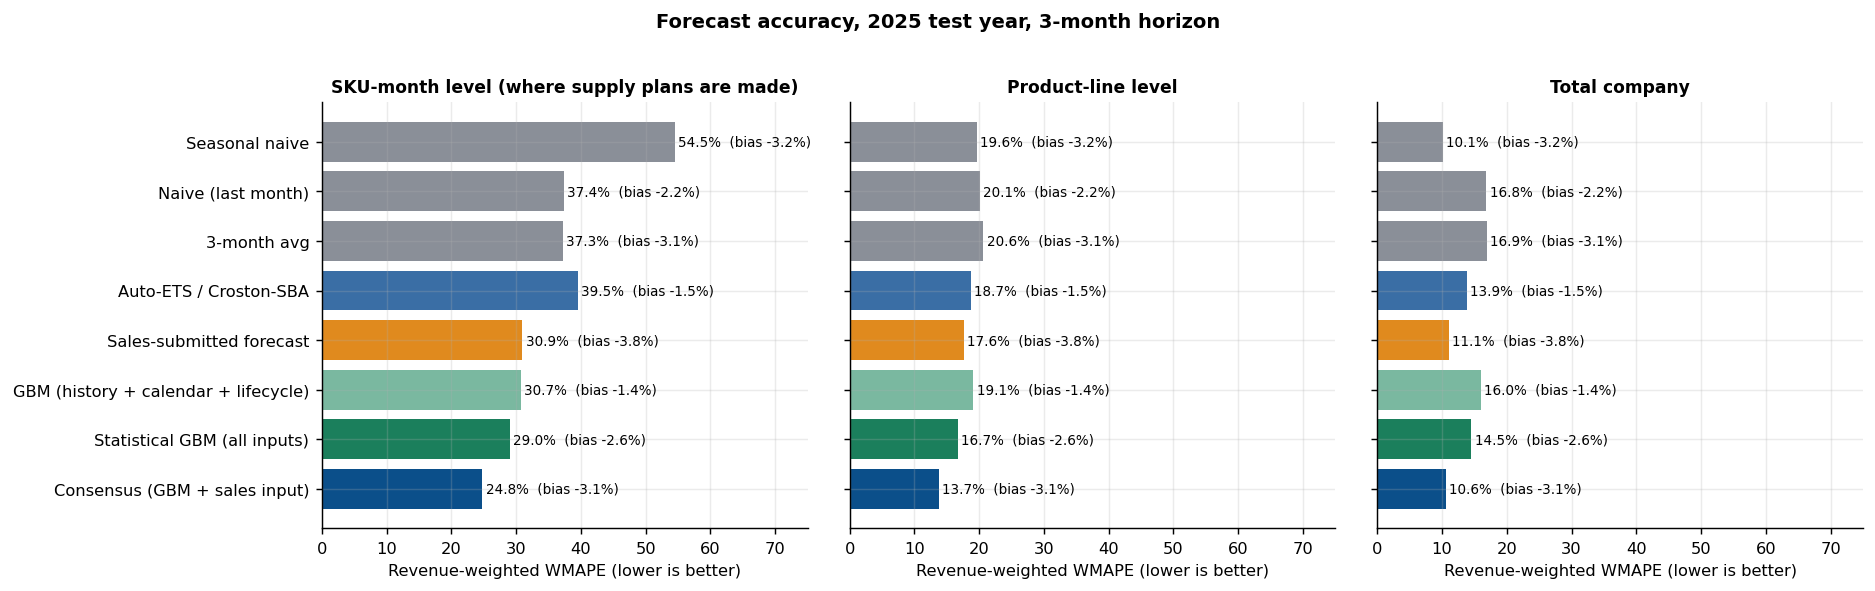

In [13]:
show('08_model_comparison.png', 1100)

### Forecast Value Added

Each step of the process is judged on whether it helped. Auto-ETS made the forecast *worse* than naive here; the global GBM and the consensus step improved it.

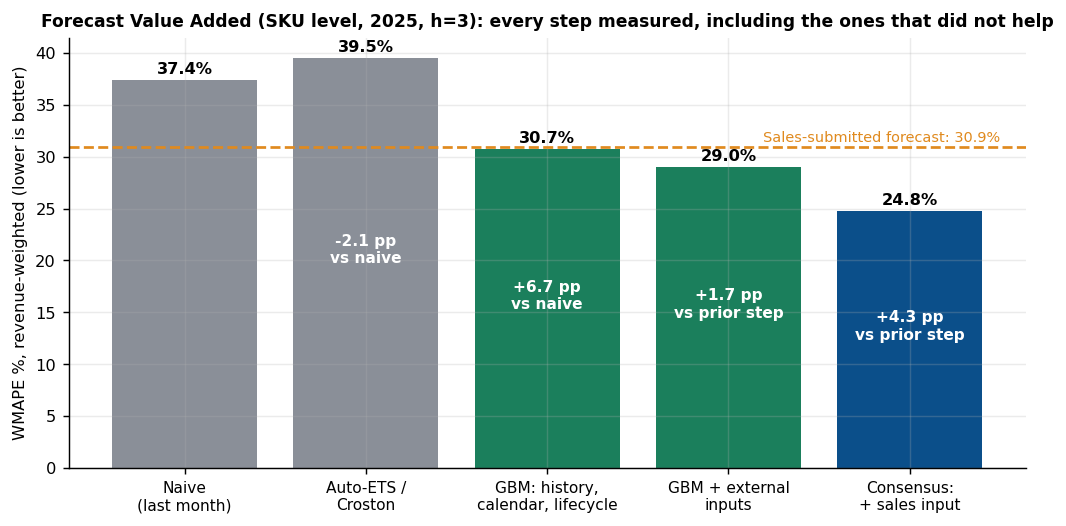

In [14]:
show('16_fva_waterfall.png', 800)

### Is the gain real or luck? Paired bootstrap over the 12 test months

In [15]:
pd.read_csv(TAB / 'bootstrap_accuracy_gap.csv')

,model,rival,gap_pp_mean,ci95_low,ci95_high,prob_model_better
0,gbm_full,naive,8.245,2.374,14.945,0.998
1,gbm_full,sales_fc,1.830,-4.889,9.072,0.695
2,gbm_full,gbm_core,1.719,0.288,3.467,0.993
3,gbm_full,stat,10.304,4.693,15.503,1.000
4,consensus,sales_fc,6.119,2.232,10.835,1.000
5,consensus,gbm_full,4.289,1.467,7.453,0.999
6,consensus,naive,12.534,6.327,19.520,1.000


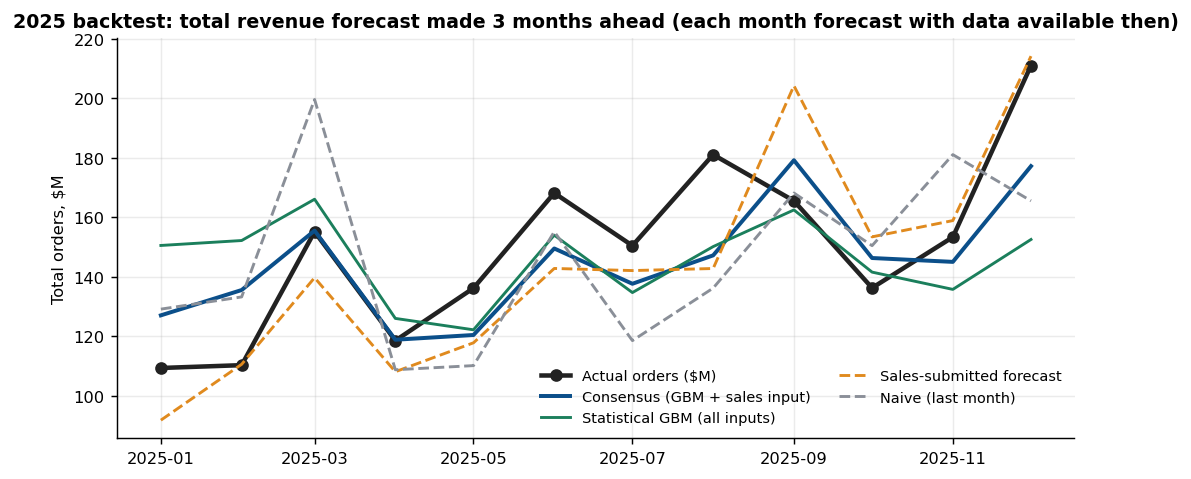

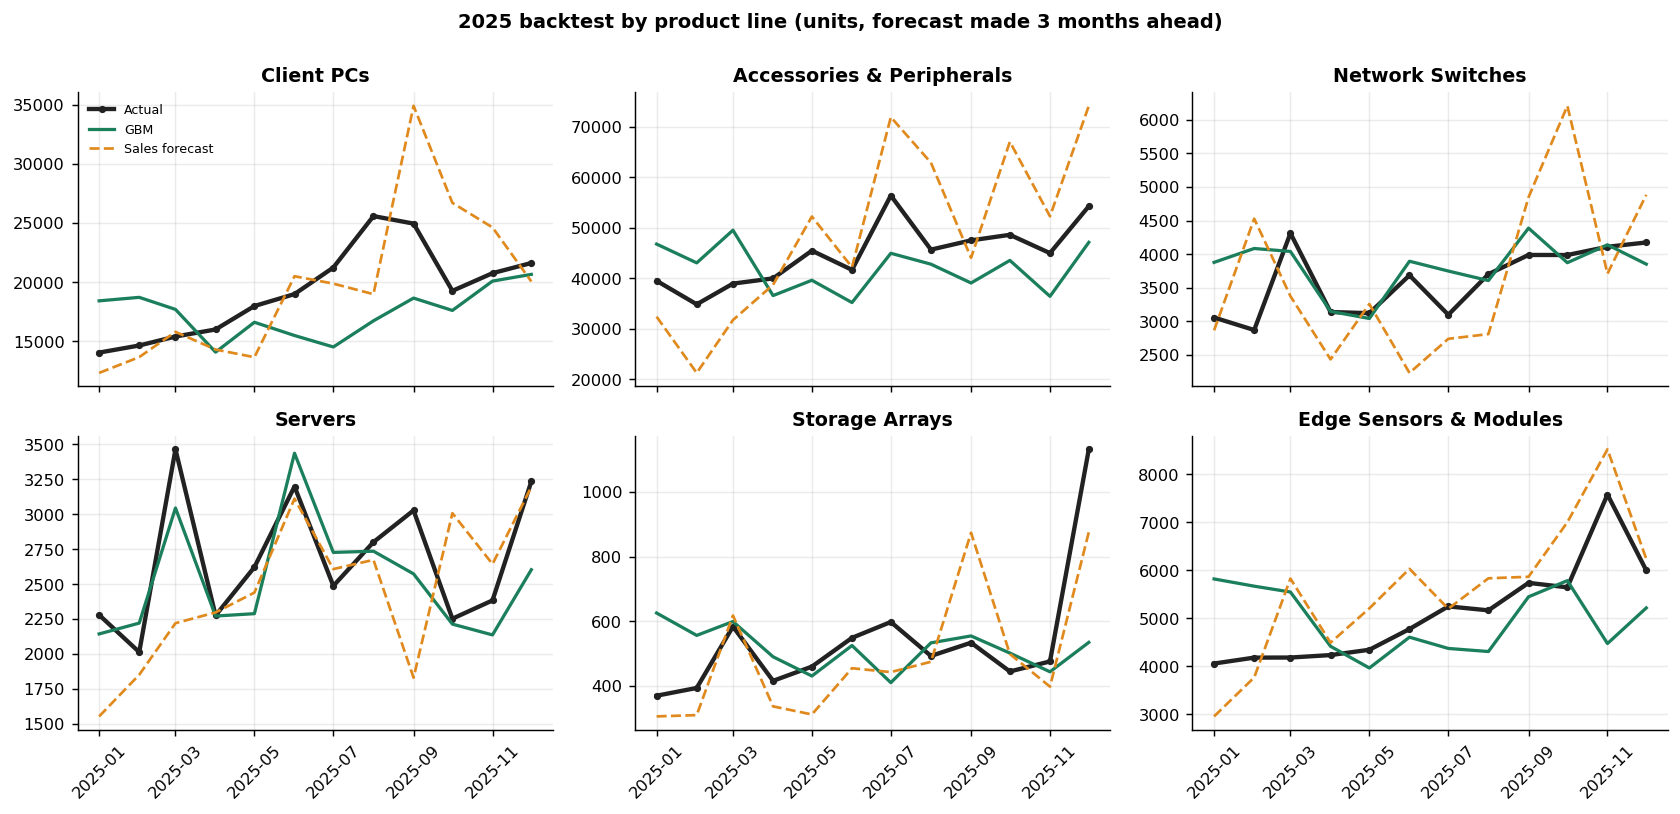

In [16]:
show('06_backtest_total_revenue.png', 900)
show('07_backtest_by_line.png', 1100)

## 5. Horizon and segments

In [17]:
acc_h = evaluate.accuracy_table(fc[(fc['T'] >= evaluate.TEST_START) & fc['model'].isin(['naive', 'stat', 'gbm_core', 'gbm_full'])], by=['h'])
acc_h.pivot(index='h', columns='model', values='wmape_rev')

model,gbm_core,gbm_full,naive,stat
h,,,,
1,0.251,0.236,0.354,0.357
3,0.307,0.290,0.374,0.395
6,0.386,0.421,0.456,0.470


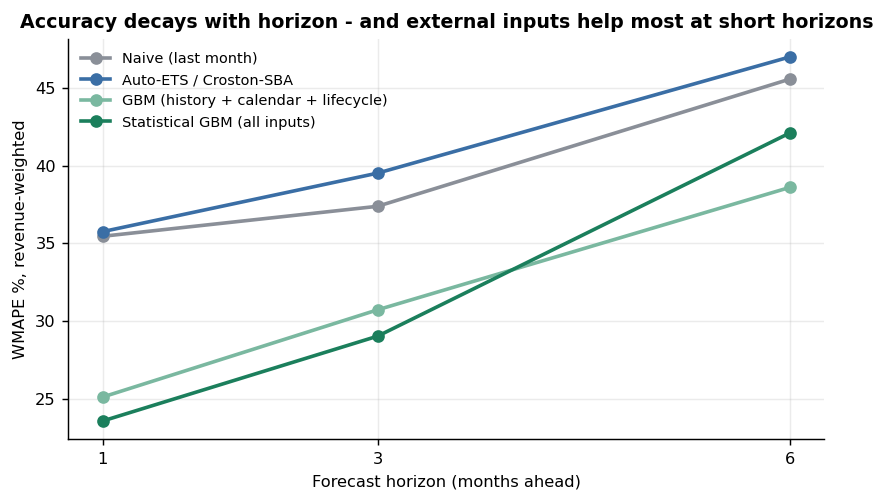

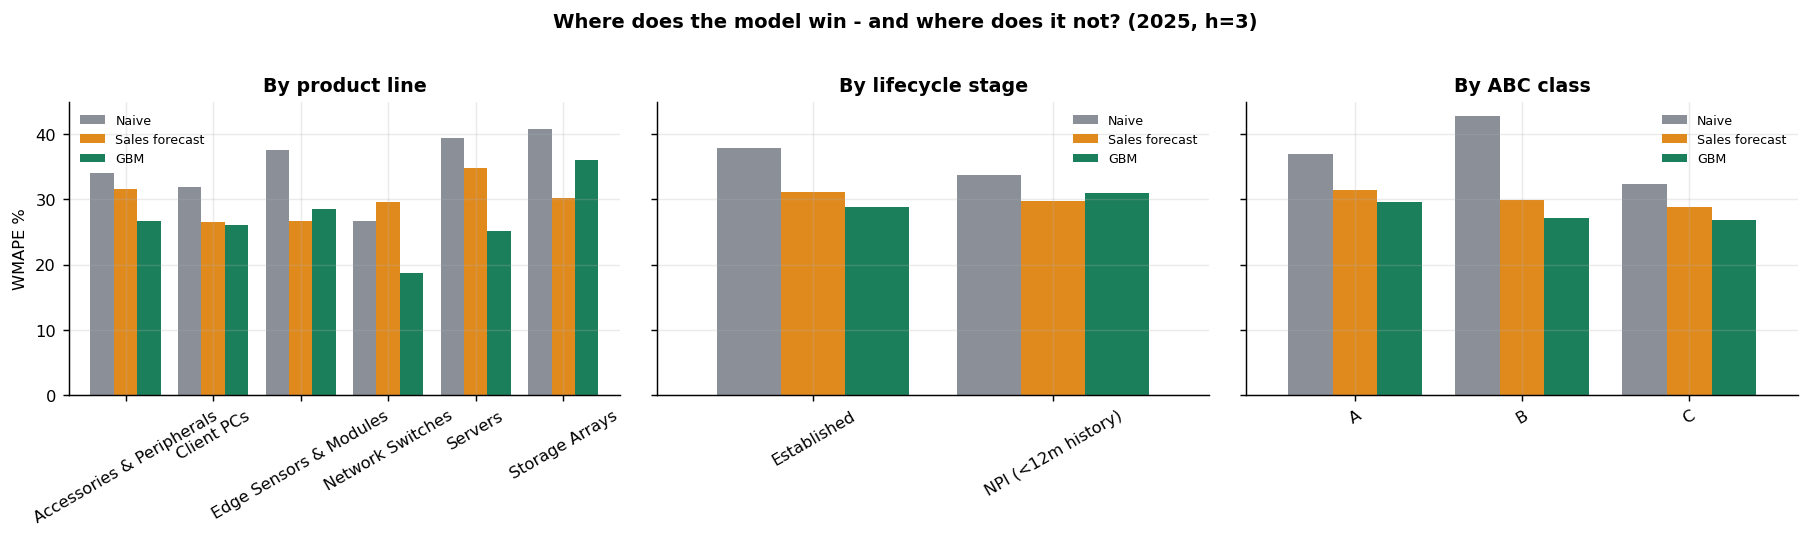

In [18]:
show('09_accuracy_by_horizon.png', 650)
show('10_accuracy_by_segment.png', 1100)

In [19]:
pd.read_csv(TAB / 'accuracy_by_line_h3.csv').pivot(index='line', columns='model', values='wmape_rev')[['naive', 'stat', 'sales_fc', 'gbm_full', 'consensus']]

model,naive,stat,sales_fc,gbm_full,consensus
line,,,,,
Accessories & Peripherals,0.341,0.382,0.316,0.267,0.190
Client PCs,0.319,0.334,0.265,0.261,0.199
Edge Sensors & Modules,0.376,0.430,0.267,0.285,0.227
Network Switches,0.267,0.278,0.297,0.186,0.205
Servers,0.395,0.319,0.348,0.251,0.250
Storage Arrays,0.408,0.502,0.303,0.361,0.282


## 6. Which inputs earn their keep?

Ablation (3-seed average): remove one input group at a time from the all-inputs GBM. **Positive = the group was helping.** Some groups did not help in this setup.

In [20]:
pd.read_csv(TAB / 'ablation_input_groups.csv')

,variant,wmape_rev,bias_rev,delta_vs_all_pp
0,History + calendar + lifecycle only (no extern...,0.307,-0.023,0.957
1,All inputs,0.297,-0.026,0.000
2,All inputs minus: Promotions & pricing plan,0.305,-0.021,0.779
3,All inputs minus: Marketing plan,0.301,-0.017,0.365
4,All inputs minus: Known events,0.300,-0.028,0.300
5,All inputs minus: Leading indicator (pipeline ...,0.295,-0.025,-0.278
6,All inputs minus: Competitor,0.296,-0.043,-0.155
7,All inputs minus: Macro & commodity,0.290,-0.032,-0.723
8,All inputs minus: Supply chain & operations,0.298,-0.019,0.041


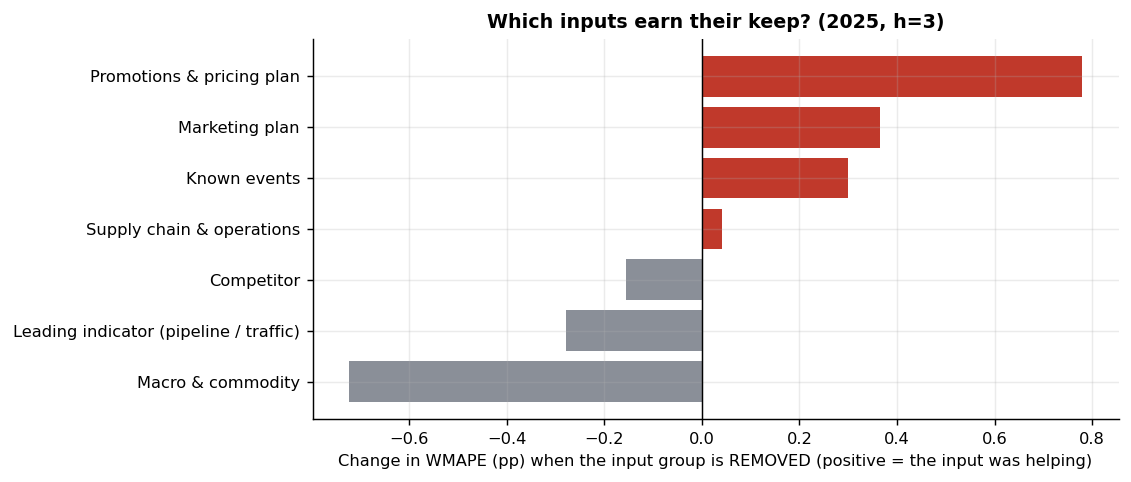

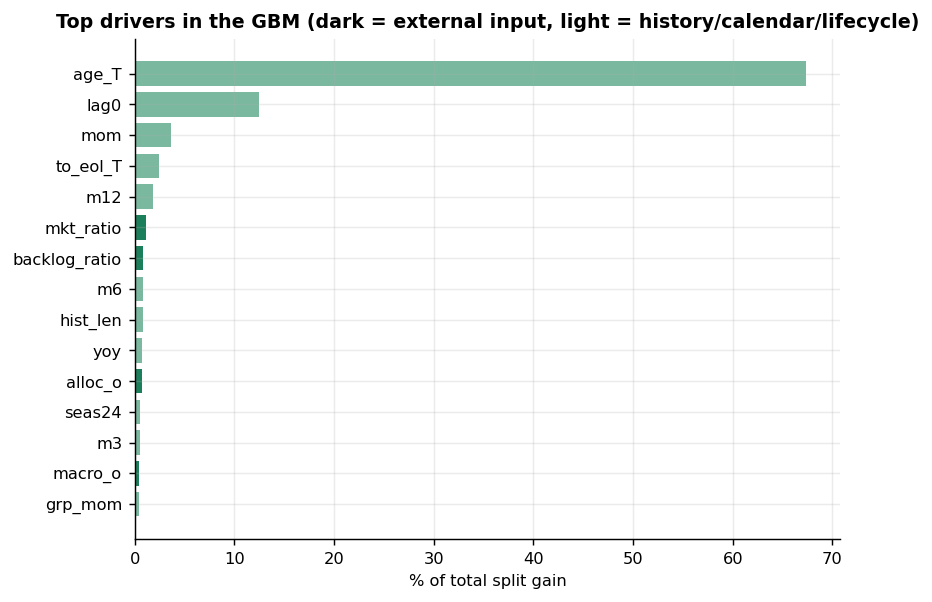

In [21]:
show('12_ablation_input_groups.png', 800)
show('11_feature_importance.png', 650)

## 7. Uncertainty for supply decisions

Quantile models give P10-P90 ranges. Raw ranges were over-confident; conformal calibration (using only errors already realised at each origin) fixes coverage.

In [22]:
pd.read_csv(TAB / 'prediction_interval_coverage.csv')

,interval,coverage,avg_width_ratio
0,Raw quantile model (nominal 80%),0.620,0.418
1,Conformalised (nominal 80%),0.826,0.571


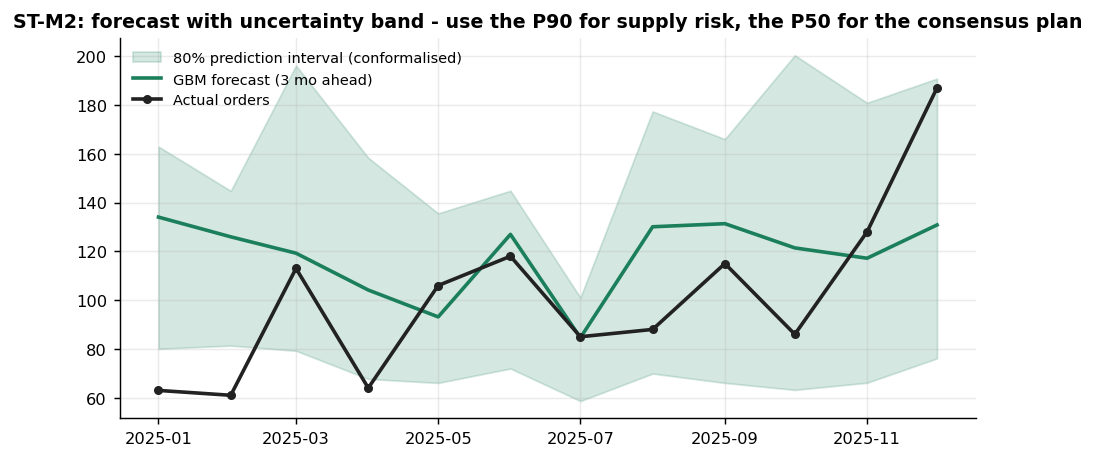

In [23]:
show('13_prediction_interval_example.png', 800)

## 8. What forecast error costs: inventory needed for the same service

One supply policy is applied to every forecast source (commit forecast + safety stock three months ahead, carry leftovers, lose unmet demand).
Safety stock `z` is swept so each model is compared **at the same fill rate**.

In [24]:
inv95 = pd.read_csv(TAB / 'inventory_needed_for_95pct_fill.csv')
inv95

,model,target_fill_rate,avg_inventory_usd_m,weeks_of_supply,carrying_cost_usd_m,inventory_vs_sales_fc_pct
0,consensus,0.950,44.331,1.243,11.083,-7.999
1,sales_fc,0.950,48.186,1.819,12.046,0.000
2,gbm_full,0.950,61.764,1.946,15.441,28.180
3,gbm_core,0.950,66.720,2.076,16.680,38.466
4,naive,0.950,71.411,2.355,17.853,48.199
5,ma3,0.950,72.806,2.605,18.202,51.096
6,stat,0.950,89.587,3.439,22.397,85.921
7,snaive,0.950,105.693,4.141,26.423,119.346


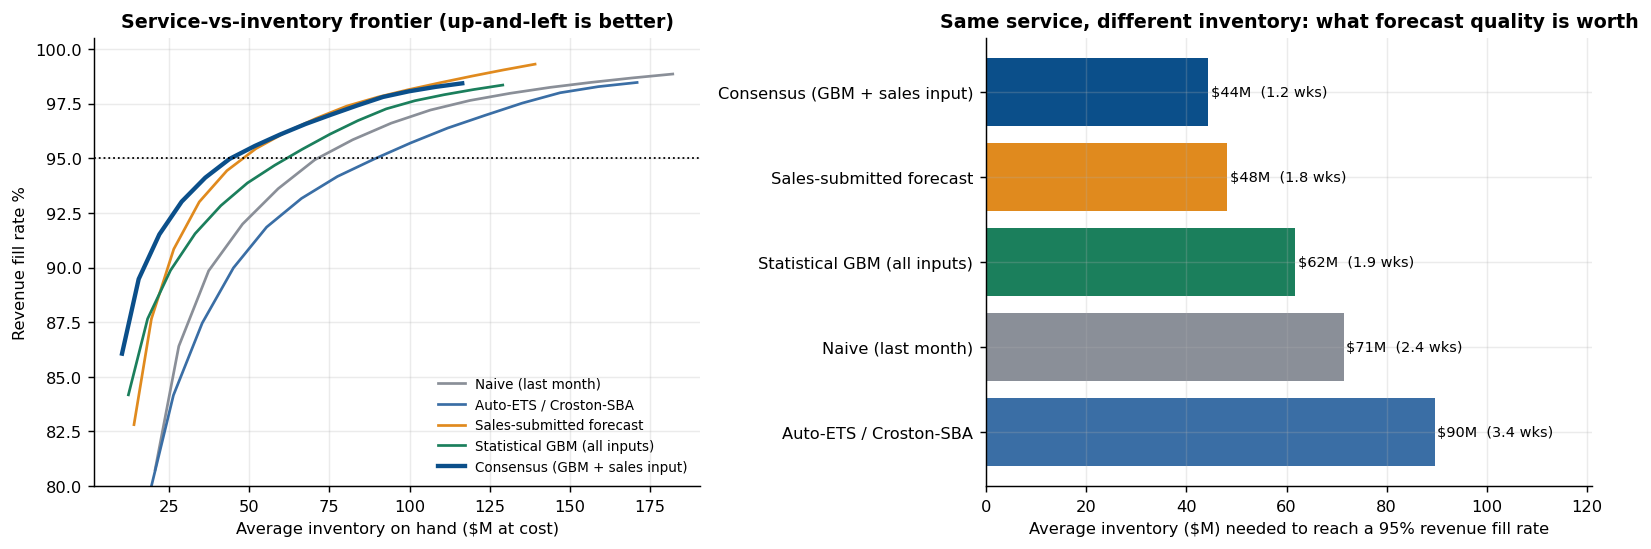

In [25]:
show('14_inventory_service_tradeoff.png', 1100)

## 9. Exception-based review

In [26]:
pd.read_csv(TAB / 'exception_report_top10.csv')[['sku', 'line', 'abs_err_rev', 'wmape', 'bias', 'share_of_total_error']]

,sku,line,abs_err_rev,wmape,bias,share_of_total_error
0,ST-P2,Storage Arrays,"74,836,596.119",0.262,-0.211,0.144
1,ST-P1,Storage Arrays,"49,079,768.011",1.309,1.309,0.094
2,ST-E2,Storage Arrays,"46,219,293.147",0.354,-0.286,0.089
3,SV-P2,Servers,"43,876,731.765",0.279,-0.003,0.084
4,ST-M2,Storage Arrays,"43,420,849.188",0.301,0.169,0.083
5,SV-M2,Servers,"31,150,128.183",0.269,-0.048,0.060
6,SV-P1,Servers,"28,814,073.393",0.300,-0.061,0.055
7,ST-M1,Storage Arrays,"22,127,007.245",0.283,0.212,0.042
8,PC-E2,Client PCs,"18,195,957.750",0.257,-0.246,0.035
9,ST-E1,Storage Arrays,"15,211,293.741",0.765,0.579,0.029


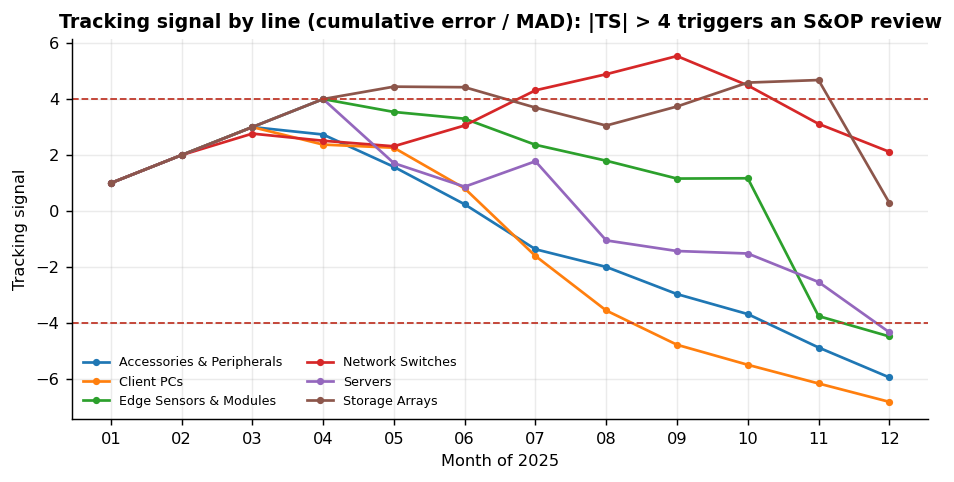

In [27]:
show('15_tracking_signal.png', 800)

## 10. Takeaways and limitations

**What the evidence supports (synthetic data, 2025 test year, 3-month horizon):**
* The consensus plan (statistical GBM + sales input, weight set on 2024) cut revenue-weighted WMAPE from 37.4% (naive) to 24.8% and needs about 38% less inventory than naive for a 95% fill rate.
* Cross-learning (one GBM over all SKUs) beat single-series statistical models; external inputs added a modest, statistically detectable gain (~1-1.7 pp), mostly from promotions, marketing and known events.
* Uncertainty ranges need calibration: raw P10-P90 covered 62% of outcomes; calibrated 83%.

**What it does not show:**
* The GBM alone is not significantly better than the simulated sales forecast; at total-company level seasonal naive is as good as anything.
* Several external inputs (leading indicator, competitor, macro) did not help; at a 6-month horizon the all-inputs model was worse.
* Everything here is synthetic. Effect sizes are assumptions, the sales forecast is simulated, and the consensus gain depends on how independent its errors are from the model's.

See `docs/methodology.md` for the full list of limitations and next steps.